<h2 style="text-align:center; font-weight: bold">Analysis on Sports Preference through news outlet across the world.</h2>
US - Washington Post and NBC News <br>UK - The Dailymail and The Guardian <br>Singapore - Channel News Asia and Straits Time<br>


<h2 style="text-align:center; font-weight: bold">Analysis on Sports Preference through news outlet across the world.</h2>
<h4 style="text-align:center; font-weight: bold">Project Proposal</h4>

<h3>1. Aims, objectives and background</h3>
<h4>1.1 Introduction</h4>
With the invention of the internet, access to the vast information highway has transformed the media landscape, compelling it to adapt to the new digital world. Even before the advent of the internet, media played a crucial role in shaping public perception and understanding of events. However, the internet has significantly amplified this influence by providing real-time access to global happenings. Despite covering the same sports events, the frequency and emphasis on specific sports can vary significantly between local and global news outlets. This project aims to analyze and compare the frequency of sports news coverage across various news outlets worldwide to uncover patterns, differences, and similarities in sports preferences in different regions.<br><br>

This project will employ several methods to analyze a diverse range of sports articles from both local and global news outlets. We will scrape text from articles across different news outlets, both local and global, and examine the frequency of coverage of specific sports. The data will be sourced from news outlets in multiple countries, where English is predominantly used. By selecting three well-known news outlets from each country, we aim to provide a more accurate representation of sports preferences among the populace.
<h3 style="font-weight: bold"h3>1.2 Aims and objectives</h3>
Within this project, I would like to explore the following:
<ul>
  <li>Data Collection and Preprocessing
    <ul>
      <li>To gather dataset of articles from selected local and global news outlets to see the differences between the two</li>
      <li>To clean and preprocess the text data to ensure accuracy and consistency in the analysis</li>
    </ul>
  </li>
  <li>Frequency Analysis
    <ul>
      <li>To perform word frequency analysis on the datasets to identify the most commonly used words in local and global news</li>
      <li>To create comparative visualizations, such as word clouds and bar charts, to highlight key differences in word usage.</li>
    </ul>
  </li>
</ul>
<h3 style="font-weight: bold">1.3 Data</h3>
<h4 style="font-weight: bold">1.3.1 Data Requirements</h4>
Three publications were chosen from each country, allowing a reasonable sample size from each country's publication. Choosing 3 types of article topics from each news publication (alternative are chosen if none are found for the particular news outlet). This allow for similar topics while having enough sample of article from each country to explore the similarity and differences. About 130 articles are chosen from each news publication which would be allow for about 300 to 400 articles for each country.
<h4 style="font-weight: bold">1.3.2 Choice of news outlet</h4>
In order to represent each country's publication outlet accurately, news outlet are chosen by the popularity of said news outlet within the country:
<ul>
  <li><h4>Local</h4>
        <ul>
            <li>The Straits Times: Leading the ranks as the top Singaporean web publisher, The Straits Times boasts an impressive 3.2 million engagements.[1]</li>
            <li>Today Online: Positioned 8th on the list, Today Online has garnered a notable 30 thousand engagements [1]</li>
            <li>Channel News Asia: Holding the 3rd spot, Channel News Asia achieves a substantial 1.6 million engagements [1]</li>
        </ul>
  </li>
    <li><h4>Global</h4>
        <ul>
            <li>Daily Mail: Ranked 5th in influence score, the Daily Mail stands among the top media outlets [2]</li>
            <li>The Guardian: Holding the 2nd position in influence score, The Guardian is a prominent media outlet [2]</li>
            <li>Sky News is ranked 6th in influence score among UK media outlets [2]</li>
        </ul>
    </li>
</ul>
<h4 style="font-weight: bold">1.3.3 How news outlet and articles are selected.</h4>
News outlets for this analysis are carefully selected based on their ratings and representation among their peers. This selection criterion ensures that the chosen outlets accurately reflect the country's perspectives and public discourse. High-rated news outlets are more likely to influence and represent the national sentiment, making their articles valuable for this comparative study.<br><br>

To achieve a comprehensive and accurate representation of word usage, articles are scraped from various categories including "features," "local news," "opinion pieces," and "sports." This diverse selection captures a wide range of topics and writing styles, enabling a thorough comparison between local and global news outlets. By including multiple categories, we ensure that the analysis covers different types of content, from factual reporting to subjective opinions, thus providing a holistic view of the language and themes prevalent in the news of each country<br>

This method of selection and categorising them for more accurate comparison and insight into the word usage between local and global news coverage
<h3 style="font-weight: bold">1.4 Ethical considerations</h3>
<h4 style="font-weight: bold">1.4.1 Ethical consideration on articles</h4>
Ethical consideration have been considered, making sure each of the website ensuring all links that had been scrapped from each of the website have not been disallowed under the robot.txt of each site.
<h4 style="font-weight: bold">1.4.2 Potential issue that may result from this analysis.</h4>
Due to the nature of a smaller data sample size, data could be skewed from multiple outlier data that have been scraped, causing inaccurate analysis and outcome due to unusually high word count or an atypical usage of certain keywords. Moreover, small sample sizes limit the ability to generalize findings to the broader population. The variability introduced by outliers becomes more pronounced, reducing the statistical power of the analysis and increasing the margin of error. This lack of representativeness and robustness can undermine the reliability and validity of the research outcomes. <br><br>
Therefore, it is crucial to acknowledge and account for the limitations imposed by small sample sizes in data analysis.

<h3>2. Webscraping</h3>
<h4>2.1 Preparing requirements for web scraping</h4>

In [1]:
import os
import requests
from bs4 import BeautifulSoup
import pandas as pd
from urllib.parse import urljoin

# Specify headers to accept gzip encoding
headers = {
    'Accept-Encoding': 'gzip, deflate',
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/58.0.3029.110 Safari/537.3'
}

<h4>2.2 Defining scraping and extraction functions</h4>

<h3>Local</h3>

<h4>Scraping article links from The Straits Time webpage</h4>

In [4]:
# Sections to scrape
sections = ['sport']

# Base URL template for the website
base_url_template = 'https://www.straitstimes.com/{}/latest?page='

# CSV file to save the extracted URLs
csv_file = 'scrape_link/local/strait_times_links.csv'

# Function to scrape a single page
def scrape_page(url):
    response = requests.get(url, headers=headers)
    
    if response.status_code == 200:
        # print(f'Successfully fetched {url}')
        soup = BeautifulSoup(response.content, 'html.parser')
        identifier = soup.find_all(class_='stretched-link')
        urls = [urljoin('https://www.straitstimes.com', link.get('href')) for link in identifier if link.get('href')]
        return urls
    else:
        print(f'Failed to fetch {url}. Status code: {response.status_code}')
        return []

# Function to save URLs to CSV
def save_to_csv(urls, file_name):
    urls_df = pd.DataFrame(urls, columns=['URL'])
    if os.path.isfile(file_name):
        urls_df.to_csv(file_name, mode='a', header=False, index=False)
    else:
        urls_df.to_csv(file_name, mode='w', header=True, index=False)

# Loop through sections and pages to scrape URLs
for section in sections:
    base_url = base_url_template.format(section)
    for page_number in range(1,11):  # Change the range as needed
        page_url = base_url + str(page_number)
        urls = scrape_page(page_url)
        if urls:
            save_to_csv(urls, csv_file)

print('Extracted URLs have been saved to', csv_file)

Extracted URLs have been saved to scrape_link/local/strait_times_links.csv


<h4 style="color:red">Scraping article links from Channel News Asia webpage</h4>

In [30]:
# Sections to scrape
sections = ['asia', 'singapore', 'sustainability', 'lifestyle', 'sport', 'world']

# Base URL template for the website
base_url_template = 'https://www.channelnewsasia.com/{}'

# CSV file to save the extracted URLs
csv_file = 'scrape_link/local/cna_links.csv'

# Function to scrape a single section
def scrape_section(section):
    url = base_url_template.format(section)
    response = requests.get(url, headers=headers)
    
    if response.status_code == 200:
        print(f'Successfully fetched section {section}')
        soup = BeautifulSoup(response.content, 'html.parser')
        identifier = soup.find_all(class_='h6__link list-object__heading-link')
        urls = [urljoin('https://www.channelnewsasia.com', link.get('href')) for link in identifier if link.get('href') and 'watch' not in link.get('href') and 'interactive' not in link.get('href') and 'listen' not in link.get('href')]
        return urls
    else:
        print(f'Failed to fetch {section}. Status code: {response.status_code}')
        return []

# Function to save URLs to CSV
def save_to_csv(urls, file_name):
    urls_df = pd.DataFrame(urls, columns=['URL'])
    if os.path.isfile(file_name):
        urls_df.to_csv(file_name, mode='a', header=False, index=False)
    else:
        urls_df.to_csv(file_name, mode='w', header=True, index=False)

# Loop through sections to scrape URLs
for section in sections:
    urls = scrape_section(section)
    if urls:
        save_to_csv(urls, csv_file)

print('Extracted URLs have been saved to', csv_file)

Successfully fetched section asia
Successfully fetched section singapore
Successfully fetched section sustainability
Successfully fetched section lifestyle
Successfully fetched section sport
Successfully fetched section world
Extracted URLs have been saved to scrape_link/local/cna_links.csv


<h3>UK</h3>

<h4>Scraping article links from The Daily Mail webpage</h4>

In [7]:
# Sections to scrape
sections = ['sport']
# sections = ['news']

# Base URL template for the website
base_url_template = 'https://www.dailymail.co.uk/{}/index.html'

# CSV file to save the extracted URLs
csv_file = 'scrape_link/uk/the_dailymail_links.csv'

# Function to scrape a single section
def scrape_section(section):
    url = base_url_template.format(section)
    response = requests.get(url, headers=headers)
    
    if response.status_code == 200:
        print(f'Successfully fetched section {section}')
        soup = BeautifulSoup(response.content, 'html.parser')
        # Find all anchor tags with an href attribute
        links = soup.find_all('a', href=True)
        # Use a set to avoid duplicate URLs
        urls = {urljoin('https://www.dailymail.co.uk/', link['href']) for link in links if '/article' in link['href']}
        return list(urls)[:100]  # Limit to the first 35 URLs
    else:
        print(f'Failed to fetch {section}. Status code: {response.status_code}')
        return []

# Function to save URLs to CSV
def save_to_csv(urls, file_name):
    if not urls:
        return
    
    urls_df = pd.DataFrame(urls, columns=['URL'])
    if os.path.isfile(file_name):
        urls_df.to_csv(file_name, mode='a', header=False, index=False)
    else:
        urls_df.to_csv(file_name, mode='w', header=True, index=False)

# Ensure the directory exists
os.makedirs(os.path.dirname(csv_file), exist_ok=True)

# Loop through sections to scrape URLs
all_urls = set()
for section in sections:
    urls = scrape_section(section)
    all_urls.update(urls)

# Save all unique URLs to CSV
save_to_csv(all_urls, csv_file)

print('Extracted URLs have been saved to', csv_file)


Successfully fetched section sport
Extracted URLs have been saved to scrape_link/uk/the_dailymail_links.csv


<h4>Scraping article links from The Guardian webpage</h4>

In [8]:
# Sections to scrape
sections = ['uk/sport']

# Base URL template for the website
base_url_template = 'https://www.theguardian.com/{}'

# CSV file to save the extracted URLs
csv_file = 'scrape_link/uk/the_guardian_links.csv'

# Function to scrape a single section
def scrape_section(section):
    url = base_url_template.format(section)
    response = requests.get(url, headers=headers)
    
    if response.status_code == 200:
        print(f'Successfully fetched section {section}')
        soup = BeautifulSoup(response.content, 'html.parser')
        # Find all anchor tags with an href attribute
        links = soup.find_all('a', href=True)
        # Use a set to avoid duplicate URLs
        urls = {urljoin('https://www.theguardian.com/', link['href']) for link in links if '/article' in link['href']}
        return urls
    else:
        print(f'Failed to fetch {section}. Status code: {response.status_code}')
        return set()

# Function to save URLs to CSV
def save_to_csv(urls, file_name):
    if not urls:
        return
    
    urls_df = pd.DataFrame(urls, columns=['URL'])
    if os.path.isfile(file_name):
        urls_df.to_csv(file_name, mode='a', header=False, index=False)
    else:
        urls_df.to_csv(file_name, mode='w', header=True, index=False)

# Ensure the directory exists
os.makedirs(os.path.dirname(csv_file), exist_ok=True)

# Loop through sections to scrape URLs
all_urls = set()
for section in sections:
    urls = scrape_section(section)
    all_urls.update(urls)

# Save all unique URLs to CSV
save_to_csv(all_urls, csv_file)

print('Extracted URLs have been saved to', csv_file)

Successfully fetched section uk/sport
Extracted URLs have been saved to scrape_link/uk/the_guardian_links.csv


<h3>US</h3>

<h4 style="color:red">Scraping article links from Washington Post webpage</h4>

In [13]:
# Sections to scrape
sections = ['sports']

# Base URL template for the website
base_url_template = 'https://www.washingtonpost.com/{}/'

# CSV file to save the extracted URLs
csv_file = 'scrape_link/us/the_washington_post_links.csv'

# Function to scrape a single section
def scrape_section(section):
    url = base_url_template.format(section)
    response = requests.get(url, headers=headers)
    
    if response.status_code == 200:
        print(f'Successfully fetched section {section}')
        soup = BeautifulSoup(response.content, 'html.parser')
        # Find all anchor tags with an href attribute
        links = soup.find_all('a', href=True)
        # Use a set to avoid duplicate URLs
        urls = {urljoin('https://www.washingtonpost.com/', link['href']) for link in links}
        return urls
    else:
        print(f'Failed to fetch {section}. Status code: {response.status_code}')
        return set()

# Function to save URLs to CSV
def save_to_csv(urls, file_name):
    if not urls:
        return
    
    urls_df = pd.DataFrame(urls, columns=['URL'])
    if os.path.isfile(file_name):
        urls_df.to_csv(file_name, mode='a', header=False, index=False)
    else:
        urls_df.to_csv(file_name, mode='w', header=True, index=False)

# Ensure the directory exists
os.makedirs(os.path.dirname(csv_file), exist_ok=True)

# Loop through sections to scrape URLs
all_urls = set()
for section in sections:
    urls = scrape_section(section)
    all_urls.update(urls)

# Save all unique URLs to CSV
save_to_csv(all_urls, csv_file)

print('Extracted URLs have been saved to', csv_file)

Successfully fetched section sports
Extracted URLs have been saved to scrape_link/us/the_washington_post_links.csv


<h4 style="color:red">Scraping article links from NBC News webpage</h4>

In [14]:
# Sections to scrape
sections = ['sports']

# Base URL template for the website
base_url_template = 'https://www.nbcnews.com/{}'

# CSV file to save the extracted URLs
csv_file = 'scrape_link/us/nbc_news_links.csv'

# Function to scrape a single section
def scrape_section(section):
    url = base_url_template.format(section)
    response = requests.get(url, headers=headers)
    
    if response.status_code == 200:
        print(f'Successfully fetched section {section}')
        soup = BeautifulSoup(response.content, 'html.parser')
        # Find all anchor tags with an href attribute
        links = soup.find_all('a', href=True)
        # Use a set to avoid duplicate URLs
        urls = {urljoin('https://www.nbcnews.com/', link['href']) for link in links}
        return urls
    else:
        print(f'Failed to fetch {section}. Status code: {response.status_code}')
        return set()

# Function to save URLs to CSV
def save_to_csv(urls, file_name):
    if not urls:
        return
    
    urls_df = pd.DataFrame(urls, columns=['URL'])
    if os.path.isfile(file_name):
        urls_df.to_csv(file_name, mode='a', header=False, index=False)
    else:
        urls_df.to_csv(file_name, mode='w', header=True, index=False)

# Ensure the directory exists
os.makedirs(os.path.dirname(csv_file), exist_ok=True)

# Loop through sections to scrape URLs
all_urls = set()
for section in sections:
    urls = scrape_section(section)
    all_urls.update(urls)

# Save all unique URLs to CSV
save_to_csv(all_urls, csv_file)

print('Extracted URLs have been saved to', csv_file)

Successfully fetched section sports
Extracted URLs have been saved to scrape_link/us/nbc_news_links.csv


<h4>2.3 Retrieving article from scraped links.</h4>
<h3>Local</h3>
<h4>Scraping article from The Straits Time link</h4>

In [15]:
# Input CSV file containing URLs
input_csv_file = 'scrape_link/local/strait_times_links.csv'
# Output CSV file to save the scraped articles
output_csv_file = 'scraped_articles/local/scraped_articles_strait_times.csv'

# Ensure the output directory exists
os.makedirs(os.path.dirname(output_csv_file), exist_ok=True)

# Function to scrape the article
def scrape_article(url):
    try:
        response = requests.get(url, headers=headers)
        response.raise_for_status()  # Raise HTTPError for bad responses (4xx or 5xx)

        soup = BeautifulSoup(response.content, 'html.parser')

        # Find the main content of the article
        article_body = soup.find('div', class_='clearfix text-formatted field field--name-field-paragraph-text field--type-text-long field--label-hidden field__item')

        if article_body:
            paragraphs = article_body.find_all('p')
            article_text = "\n\n".join([para.get_text() for para in paragraphs])
            return article_text
        else:
            return ''
    except requests.exceptions.RequestException as e:
        return ''

# Read URLs from the CSV file
df_urls = pd.read_csv(input_csv_file)

# Check if 'URL' column exists
count = 0

if 'URL' not in df_urls.columns:
    print(f'No "URL" column found in {input_csv_file}')
else:
    urls = df_urls['URL'].tolist()

    # List to store all articles
    articles = []

    # Loop through each URL to scrape the article content
    for idx, url in enumerate(urls):
        article_content = scrape_article(url)

        if article_content:
            articles.append({'URL': url, 'Content': article_content})
            count+=1

    # Save all scraped articles to a single CSV file
    df_articles = pd.DataFrame(articles)
    df_articles.to_csv(output_csv_file, index=False, encoding='utf-8')
    
    print(f'All articles have been scraped and saved to {output_csv_file}, a total of {count} articles was scraped.')


All articles have been scraped and saved to scraped_articles/local/scraped_articles_strait_times.csv, a total of 100 articles was scraped.


<h4>Scraping article from Channel News Asia link</h4>

In [16]:
# Input CSV file containing URLs
input_csv_file = 'scrape_link/local/cna_links.csv'
# Output CSV file to save the scraped articles
output_csv_file = 'scraped_articles/local/scraped_articles_cna.csv'

# Ensure the output directory exists
os.makedirs(os.path.dirname(output_csv_file), exist_ok=True)

# Function to scrape the article
def scrape_article(url):
    try:
        response = requests.get(url, headers=headers)
        response.raise_for_status()  # Raise HTTPError for bad responses (4xx or 5xx)

        soup = BeautifulSoup(response.content, 'html.parser')

        # Find the main content of the article
        article_body = soup.find('section', class_='block block-layout-builder block-field-blocknodearticlefield-content clearfix')

        if article_body:
            paragraphs = article_body.find_all('p')
            article_text = "\n\n".join([para.get_text() for para in paragraphs])
            return article_text
        else:
            print('Failed to find the article content for URL:', url)
            return ''
    except requests.exceptions.RequestException as e:
        return ''

# Read URLs from the CSV file
df_urls = pd.read_csv(input_csv_file)

# Check if 'URL' column exists
count = 0

if 'URL' not in df_urls.columns:
    print(f'No "URL" column found in {input_csv_file}')
else:
    urls = df_urls['URL'].tolist()

    # List to store all articles
    articles = []

    # Loop through each URL to scrape the article content
    for idx, url in enumerate(urls):
        article_content = scrape_article(url)

        if article_content:
            articles.append({'URL': url, 'Content': article_content})
            count+=1

    # Save all scraped articles to a single CSV file
    df_articles = pd.DataFrame(articles)
    df_articles.to_csv(output_csv_file, index=False, encoding='utf-8')
    
    print(f'All articles have been scraped and saved to {output_csv_file}, a total of {count} articles was scraped.')

FileNotFoundError: [Errno 2] No such file or directory: 'scrape_link/local/cna_links.csv'

<h3>UK</h3>

<h4>Scraping article from The Daily Mail link</h4>

In [17]:
# Input CSV file containing URLs
input_csv_file = 'scrape_link/uk/the_dailymail_links.csv'
# Output CSV file to save the scraped articles
output_csv_file = 'scraped_articles/uk/scraped_articles_dailymail.csv'

# Ensure the output directory exists
os.makedirs(os.path.dirname(output_csv_file), exist_ok=True)

# Function to scrape the article
def scrape_article(url):
    try:
        response = requests.get(url, headers=headers)
        response.raise_for_status()  # Raise HTTPError for bad responses (4xx or 5xx)

        soup = BeautifulSoup(response.content, 'html.parser')

        # Find the main content of the article
        article_body = soup.find('div', itemprop='articleBody')

        if article_body:
            paragraphs = article_body.find_all('p')
            article_text = "\n\n".join([para.get_text() for para in paragraphs])
            return article_text
        else:
            print('Failed to find the article content for URL:', url)
            return ''
    except requests.exceptions.RequestException as e:
        return ''

# Read URLs from the CSV file
df_urls = pd.read_csv(input_csv_file)

# Check if 'URL' column exists
count = 0

if 'URL' not in df_urls.columns:
    print(f'No "URL" column found in {input_csv_file}')
else:
    urls = df_urls['URL'].tolist()

    # List to store all articles
    articles = []

    # Loop through each URL to scrape the article content
    for idx, url in enumerate(urls):
        article_content = scrape_article(url)

        if article_content:
            articles.append({'URL': url, 'Content': article_content})
            count+=1

    # Save all scraped articles to a single CSV file
    df_articles = pd.DataFrame(articles)
    df_articles.to_csv(output_csv_file, index=False, encoding='utf-8')
    
    print(f'All articles have been scraped and saved to {output_csv_file}, a total of {count} articles was scraped.')


All articles have been scraped and saved to scraped_articles/uk/scraped_articles_dailymail.csv, a total of 100 articles was scraped.


<h4>Scraping article from The Guardian link</h4>

In [18]:
# Input CSV file containing URLs
input_csv_file = 'scrape_link/uk/the_guardian_links.csv'
# Output CSV file to save the scraped articles
output_csv_file = 'scraped_articles/uk/scraped_articles_guardian.csv'

# Ensure the output directory exists
os.makedirs(os.path.dirname(output_csv_file), exist_ok=True)

# Function to scrape the article
def scrape_article(url):
    try:
        response = requests.get(url, headers=headers)
        response.raise_for_status()  # Raise HTTPError for bad responses (4xx or 5xx)

        soup = BeautifulSoup(response.content, 'html.parser')

        # Find the main content of the article
        article_body = soup.find('div', class_='article-body-commercial-selector')

        if article_body:
            paragraphs = article_body.find_all('p')
            article_text = "\n\n".join([para.get_text() for para in paragraphs])
            return article_text
        else:
            print('Failed to find the article content for URL:', url)
            return ''
    except requests.exceptions.RequestException as e:
        return ''

# Read URLs from the CSV file
df_urls = pd.read_csv(input_csv_file)

# Check if 'URL' column exists
count = 0

if 'URL' not in df_urls.columns:
    print(f'No "URL" column found in {input_csv_file}')
else:
    urls = df_urls['URL'].tolist()

    # List to store all articles
    articles = []

    # Loop through each URL to scrape the article content
    for idx, url in enumerate(urls):
        article_content = scrape_article(url)

        if article_content:
            articles.append({'URL': url, 'Content': article_content})
            count+=1

    # Save all scraped articles to a single CSV file
    df_articles = pd.DataFrame(articles)
    df_articles.to_csv(output_csv_file, index=False, encoding='utf-8')
    
    print(f'All articles have been scraped and saved to {output_csv_file}, a total of {count} articles was scraped.')


All articles have been scraped and saved to scraped_articles/uk/scraped_articles_guardian.csv, a total of 62 articles was scraped.


<h3>US</h3>

<h4>Scraping article from Washington Post link</h4>

<h4>Scraping article from NBC News link</h4>

<h3>3. Data cleaning and processing</h3>
<h4>3.1 Preparing requirements for data cleaning</h4>

In [19]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
import re

# Download necessary NLTK resources
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\koo_j\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\koo_j\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\koo_j\AppData\Roaming\nltk_data...


True

<h4>Cleaning of text data for local news articles</h4>

In [8]:
# Load stop words
stop_words = set(stopwords.words('english'))

# Lemmatizer
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    # Lowercase
    text = text.lower()
    # Remove non-alphanumeric characters
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
    # Tokenize text
    tokens = word_tokenize(text)
    # Remove stopwords and lemmatize
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return ' '.join(tokens)

# List of input file paths
input_files = [
    'scraped_articles/local/scraped_articles_cna.csv',
    'scraped_articles/local/scraped_articles_strait_times.csv',
    # Add more file paths as needed
]

# Output file path
output_csv_file = 'cleaned_data/local/cleaned_articles_combined_local.csv'

# Ensure the output directory exists
os.makedirs(os.path.dirname(output_csv_file), exist_ok=True)

# List to hold cleaned DataFrames
cleaned_data_frames = []

# Process each input file
for input_csv_file in input_files:
    # Read the CSV file
    df = pd.read_csv(input_csv_file)
    
    # Apply the cleaning function to the 'Content' column
    df['cleaned_article'] = df['Content'].apply(clean_text)
    
    # Select only the 'URL' and 'cleaned_article' columns
    cleaned_df = df[['cleaned_article']]
    
    # Append the cleaned DataFrame to the list
    cleaned_data_frames.append(cleaned_df)
    
    print(f'Processed and cleaned data from {input_csv_file}')

# Concatenate all cleaned DataFrames into a single DataFrame
combined_cleaned_df = pd.concat(cleaned_data_frames, ignore_index=True)

# Save the combined cleaned data to a single CSV file
combined_cleaned_df.to_csv(output_csv_file, index=False)

print(f'Combined cleaned articles have been saved to {output_csv_file}')


Processed and cleaned data from scraped_articles/local/scraped_articles_cna.csv
Processed and cleaned data from scraped_articles/local/scraped_articles_strait_times.csv
Processed and cleaned data from scraped_articles/local/scraped_articles_today.csv
Combined cleaned articles have been saved to cleaned_data/local/cleaned_articles_combined_local.csv


<h4>Cleaning of text data for UK news articles</h4>

In [21]:
# Load stop words
stop_words = set(stopwords.words('english'))

# Lemmatizer
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    # Lowercase
    text = text.lower()
    # Remove non-alphanumeric characters
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
    # Tokenize text
    tokens = word_tokenize(text)
    # Remove stopwords and lemmatize
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return ' '.join(tokens)

# List of input file paths
input_files = [
    'scraped_articles/uk/scraped_articles_dailymail.csv',
    'scraped_articles/uk/scraped_articles_guardian.csv',
    # Add more file paths as needed
]

# Output file path
output_csv_file = 'cleaned_data/uk/cleaned_articles_combined_uk.csv'

# Ensure the output directory exists
os.makedirs(os.path.dirname(output_csv_file), exist_ok=True)

# List to hold cleaned DataFrames
cleaned_data_frames = []

# Process each input file
for input_csv_file in input_files:
    # Read the CSV file
    df = pd.read_csv(input_csv_file)
    
    # Apply the cleaning function to the 'Content' column
    df['cleaned_article'] = df['Content'].apply(clean_text)
    
    # Select only the 'URL' and 'cleaned_article' columns
    cleaned_df = df[['cleaned_article']]
    
    # Append the cleaned DataFrame to the list
    cleaned_data_frames.append(cleaned_df)
    
    print(f'Processed and cleaned data from {input_csv_file}')

# Concatenate all cleaned DataFrames into a single DataFrame
combined_cleaned_df = pd.concat(cleaned_data_frames, ignore_index=True)

# Save the combined cleaned data to a single CSV file
combined_cleaned_df.to_csv(output_csv_file, index=False)

print(f'Combined cleaned articles have been saved to {output_csv_file}')

Processed and cleaned data from scraped_articles/uk/scraped_articles_dailymail.csv
Processed and cleaned data from scraped_articles/uk/scraped_articles_guardian.csv
Combined cleaned articles have been saved to cleaned_data/uk/cleaned_articles_combined_uk.csv


<h4>Cleaning of text data for US news articles</h4>

In [ ]:
# Load stop words
stop_words = set(stopwords.words('english'))

# Lemmatizer
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    # Lowercase
    text = text.lower()
    # Remove non-alphanumeric characters
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
    # Tokenize text
    tokens = word_tokenize(text)
    # Remove stopwords and lemmatize
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return ' '.join(tokens)

# List of input file paths
input_files = [
    'scraped_articles/us/',
    'scraped_articles/us/'
    # Add more file paths as needed
]

# Output file path
output_csv_file = 'cleaned_data/uk/cleaned_articles_combined_uk.csv'

# Ensure the output directory exists
os.makedirs(os.path.dirname(output_csv_file), exist_ok=True)

# List to hold cleaned DataFrames
cleaned_data_frames = []

# Process each input file
for input_csv_file in input_files:
    # Read the CSV file
    df = pd.read_csv(input_csv_file)
    
    # Apply the cleaning function to the 'Content' column
    df['cleaned_article'] = df['Content'].apply(clean_text)
    
    # Select only the 'URL' and 'cleaned_article' columns
    cleaned_df = df[['cleaned_article']]
    
    # Append the cleaned DataFrame to the list
    cleaned_data_frames.append(cleaned_df)
    
    print(f'Processed and cleaned data from {input_csv_file}')

# Concatenate all cleaned DataFrames into a single DataFrame
combined_cleaned_df = pd.concat(cleaned_data_frames, ignore_index=True)

# Save the combined cleaned data to a single CSV file
combined_cleaned_df.to_csv(output_csv_file, index=False)

print(f'Combined cleaned articles have been saved to {output_csv_file}')

<h4>3.2 Unique count of words from each regional news outlets</h4>

<h4>Getting the count of each word from local article</h4>

In [35]:
import pandas as pd
from collections import Counter

# Path to the cleaned CSV file
input_csv_file = 'cleaned_data/local/cleaned_articles_combined_local.csv'

# Read the CSV file
df = pd.read_csv(input_csv_file)

# Check if the 'cleaned_article' column exists
if 'cleaned_article' not in df.columns:
    print("The specified column 'cleaned_article' does not exist in the CSV file.")
    exit()

# Concatenate all cleaned articles into a single string
all_text = ' '.join(df['cleaned_article'].dropna())

# Split the text into words
words = all_text.split()

# Count the frequency of each word
word_count = Counter(words)

# Convert the word count dictionary to a DataFrame
word_count_df = pd.DataFrame(list(word_count.items()), columns=['Word', 'Count'])

# Sort the DataFrame by 'Count' in descending order
word_count_df.sort_values(by='Count', ascending=False, inplace=True)

# Path to save the word count CSV
output_word_count_csv = 'cleaned_data/local/word_count_local.csv'

# Save the word count to a CSV file
word_count_df.to_csv(output_word_count_csv, index=False)

# Print the entire sorted list of word frequencies as a table without index
top_20_words = word_count_df.head(20)
print("Full List of Word Frequencies:")
print(top_20_words.to_string(index=False))
print(" ")
print(f"Word count has been saved to {output_word_count_csv}")


Full List of Word Frequencies:
     Word  Count
     said   1219
singapore    683
     also    517
     year    426
       mr    385
      may    375
     time    348
      one    346
      per    308
     cent    278
    would    250
   people    236
    first    227
    added    225
     work    220
      two    215
    child    212
     home    207
     like    197
      new    196
 
Word count has been saved to cleaned_data/local/word_count_local.csv


<h4>Getting the count of each word from UK article</h4>

In [22]:
import pandas as pd
from collections import Counter

# Path to the cleaned CSV file
input_csv_file = 'cleaned_data/uk/cleaned_articles_combined_uk.csv'

# Read the CSV file
df = pd.read_csv(input_csv_file)

# Check if the 'cleaned_article' column exists
if 'cleaned_article' not in df.columns:
    print("The specified column 'cleaned_article' does not exist in the CSV file.")
    exit()

# Concatenate all cleaned articles into a single string
all_text = ' '.join(df['cleaned_article'].dropna())

# Split the text into words
words = all_text.split()

# Count the frequency of each word
word_count = Counter(words)

# Convert the word count dictionary to a DataFrame
word_count_df = pd.DataFrame(list(word_count.items()), columns=['Word', 'Count'])

# Sort the DataFrame by 'Count' in descending order
word_count_df.sort_values(by='Count', ascending=False, inplace=True)

# Path to save the word count CSV
output_word_count_csv = 'cleaned_data/uk/word_count_uk.csv'

# Save the word count to a CSV file
word_count_df.to_csv(output_word_count_csv, index=False)

# Print the entire sorted list of word frequencies as a table without index
top_20_words = word_count_df.head(20)
print("Full List of Word Frequencies:")
print(top_20_words.to_string(index=False))
print(" ")
print(f"Word count has been saved to {output_word_count_csv}")


Full List of Word Frequencies:
      Word  Count
   england    542
      game    422
       one    380
    player    375
      team    365
      time    298
      year    295
     first    290
      said    276
      last    272
     would    250
       fan    238
      also    226
     group    219
       two    219
     world    215
      euro    196
tournament    184
      play    181
     right    178
 
Word count has been saved to cleaned_data/uk/word_count_uk.csv


<h3>4. Exploratory data analysis</h3>
<h4>4.1 Wordclouds</h4>

<h4>Preparing requirements for data analysis</h4>

In [28]:
import pandas as pd
from wordcloud import WordCloud
import matplotlib.pyplot as plt

<h3>Local</h3>

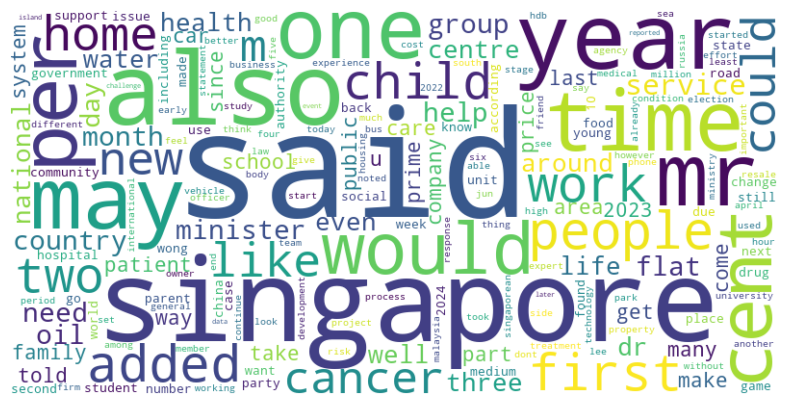

In [23]:
# Path to the CSV file with word counts
csv_file_path = 'cleaned_data/local/word_count_local.csv'

# Load data from CSV
df = pd.read_csv(csv_file_path)

# Convert DataFrame to dictionary with words as keys and counts as values
word_freq = dict(zip(df.Word, df.Count))

# Generate a word cloud image
wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(word_freq)

# Display the generated image using matplotlib
plt.figure(figsize=(10, 5))  # Adjust to appropriate dimensions
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')  # No axis for a cleaner presentation
plt.show()

<h3>UK</h3>

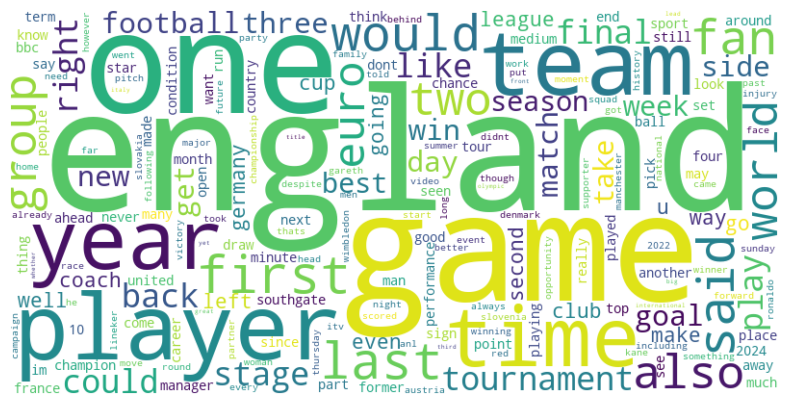

In [29]:
# Path to the CSV file with word counts
csv_file_path = 'cleaned_data/uk/word_count_uk.csv'

# Load data from CSV
df = pd.read_csv(csv_file_path)

# Convert DataFrame to dictionary with words as keys and counts as values
word_freq = dict(zip(df.Word, df.Count))

# Generate a word cloud image
wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(word_freq)

# Display the generated image using matplotlib
plt.figure(figsize=(10, 5))  # Adjust to appropriate dimensions
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')  # No axis for a cleaner presentation
plt.show()

<h4>4.2 Comparative Frequency Analysis</h4>

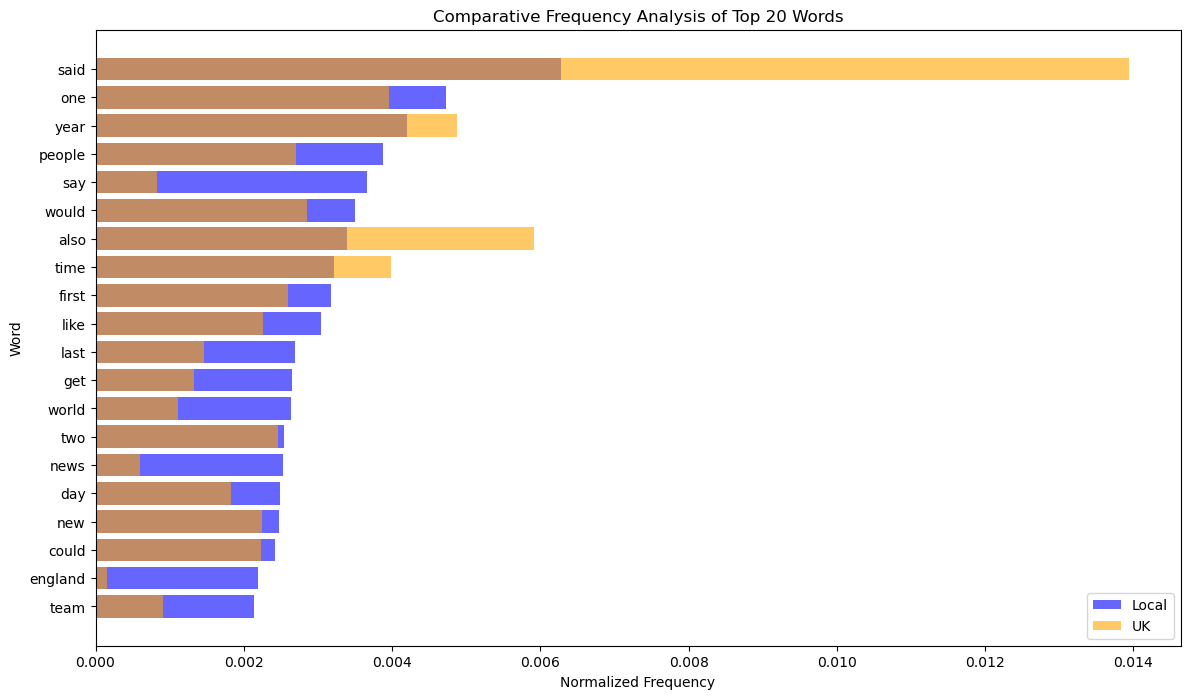

In [26]:
# Load the data from the provided CSV files
file_path_local = 'cleaned_data/uk/word_count_uk.csv'
file_path_uk = 'cleaned_data/local/word_count_local.csv'

df_local = pd.read_csv(file_path_local)
df_uk = pd.read_csv(file_path_uk)

# Merge the dataframes on the 'Word' column
df_merged = pd.merge(df_local, df_uk, on='Word', how='outer', suffixes=('_local', '_uk')).fillna(0)

# Calculate the total counts for normalization
total_local = df_local['Count'].sum()
total_uk = df_uk['Count'].sum()

# Normalize the counts
df_merged['Count_local_normalized'] = df_merged['Count_local'] / total_local
df_merged['Count_uk_normalized'] = df_merged['Count_uk'] / total_uk

# Sort by the local normalized count for better visualization
df_merged_sorted = df_merged.sort_values(by='Count_local_normalized', ascending=False).head(20)

# Plot the comparative frequency analysis
plt.figure(figsize=(14, 8))
plt.barh(df_merged_sorted['Word'], df_merged_sorted['Count_local_normalized'], color='blue', alpha=0.6, label='Local')
plt.barh(df_merged_sorted['Word'], df_merged_sorted['Count_uk_normalized'], color='orange', alpha=0.6, label='UK')
plt.xlabel('Normalized Frequency')
plt.ylabel('Word')
plt.title('Comparative Frequency Analysis of Top 20 Words')
plt.legend()
plt.gca().invert_yaxis()
plt.show()

<h4>4.3 Differential Word Analysis</h4>

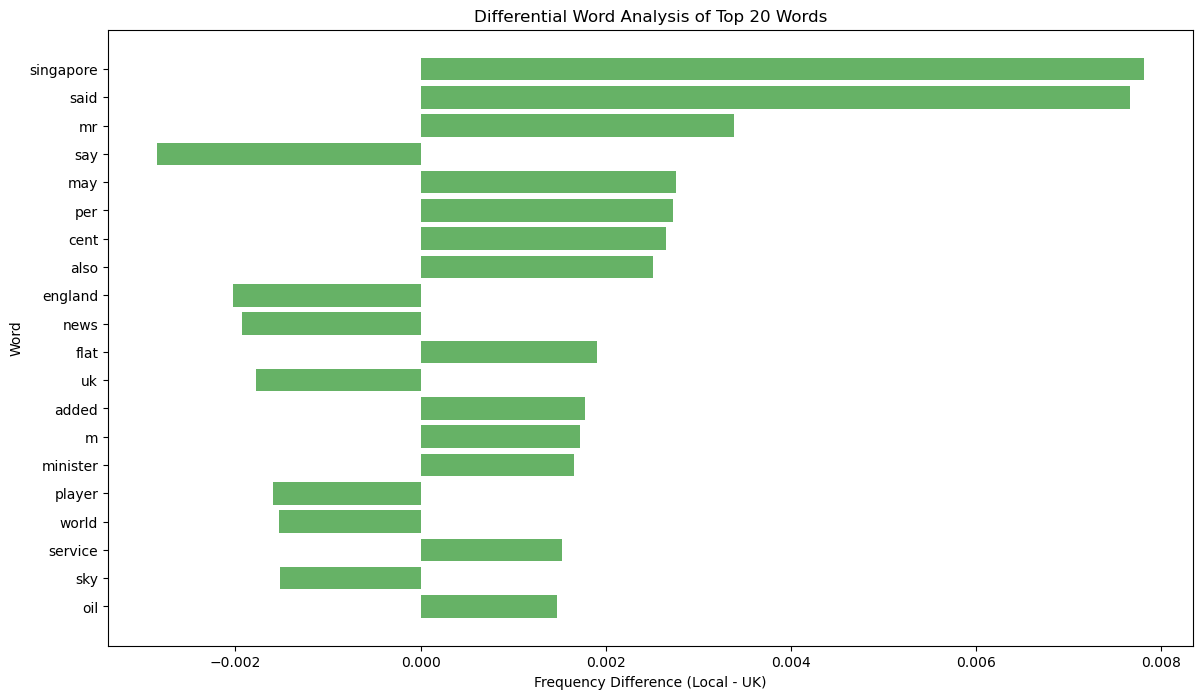

In [31]:
# Load the data from the provided CSV files
file_path_local = 'cleaned_data/local/word_count_local.csv'
file_path_uk = 'cleaned_data/uk/word_count_uk.csv'

df_local = pd.read_csv(file_path_local)
df_uk = pd.read_csv(file_path_uk)

# Merge the dataframes on the 'Word' column
df_merged = pd.merge(df_local, df_uk, on='Word', how='outer', suffixes=('_local', '_uk')).fillna(0)

# Calculate the total counts for normalization
total_local = df_local['Count'].sum()
total_uk = df_uk['Count'].sum()

# Normalize the counts
df_merged['Count_local_normalized'] = df_merged['Count_local'] / total_local
df_merged['Count_uk_normalized'] = df_merged['Count_uk'] / total_uk

# Calculate the difference in normalized frequencies
df_merged['Frequency_Difference'] = df_merged['Count_local_normalized'] - df_merged['Count_uk_normalized']

# Sort by the absolute value of the frequency difference for better visualization
df_merged_sorted_diff = df_merged.reindex(df_merged['Frequency_Difference'].abs().sort_values(ascending=False).index).head(20)

# Plot the differential word analysis
plt.figure(figsize=(14, 8))
plt.barh(df_merged_sorted_diff['Word'], df_merged_sorted_diff['Frequency_Difference'], color='green', alpha=0.6)
plt.xlabel('Frequency Difference (Local - UK)')
plt.ylabel('Word')
plt.title('Differential Word Analysis of Top 20 Words')
plt.gca().invert_yaxis()
plt.show()

<h3>6. Summary</h3>
<h4>6.1 Conclusions</h4>

In relation to this project on word analysis between news outlets, the analysis has identified certain words that are frequently found in both Singaporean and UK journalism. However, it is important to note that without a larger dataset, the conclusions drawn from our analysis may not be entirely definitive.

The current dataset, while informative, may be influenced by outliers which could potentially skew the data. These anomalies might result from the limited scope of the sample, affecting the accuracy and reliability of the findings. To mitigate this, a more extensive collection of articles from a wider range of sources and over a longer period would be necessary to ensure a more robust and representative analysis.

Expanding the dataset would allow for a more comprehensive examination of word usage patterns, reducing the impact of outliers and providing a clearer picture of the linguistic tendencies in both Singaporean and UK journalism. This would ultimately enhance the validity of our comparative analysis and provide more conclusive insights into the similarities and differences in word usage between the two regions.

<h3>7. References and Resources</h3>
<h4>7.1 References</h4>

[1]The top publishers in Singapore for Q2 2023: https://www.newswhip.com/2023/07/the-top-publishers-in-singapore-for-q2-2023/ <br>
[2]Top 100 media outlets in the UK: https://prowly.com/profiles/outlet-lists/top-100-media-outlets-in-the-uk <br>

<h4>7.2 Resources</h4>

Bird, S., Klein, E., & Loper, E. (2023). Natural Language Toolkit. Retrieved from https://www.nltk.org/